# mESC CTCF-WAPL depletion (0hr vs 6hr): aggregate contact maps and jet strength violin plot

In [1]:
import sys
sys.path.append('..')
from utils.plotting import plot_n_hic, genomic_labels, genomic_labels2
from func_plotting import add_pairwise_sig
from func_pileup import get_pileups, remove_stacks, generate_bed_3

import os
import yaml
import numpy as np
import pandas as pd
import bioframe as bf
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator

In [2]:
cf = """
samples:

  GSM5512841_HiC.05_CTCFWAPL_0h: 
    file: "/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/GSM5512841_HiC.05_CTCFWAPL_0h.hic"
    genome: "mm10"
    norm: "VC_SQRT"
    res: "25000" 
    q_val: "0.5"
    q_val_white: "0.1"

  GSM5512842_HiC.06_CTCFWAPL_6h: 
    file: "/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/GSM5512842_HiC.06_CTCFWAPL_6h.hic"
    genome: "mm10"
    norm: "VC_SQRT"
    res: "25000" 
    q_val: "0.5"
    q_val_white: "0.1"
"""

samples = yaml.safe_load(cf)["samples"]
names = list(samples.keys())

In [3]:
output_name = "v2.0.3"
data_name = "mESC CTCF-WAPL depletion all pairs"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

names_abrev = ["0hr", "6hr"]
names_abrev_dict = dict(zip(names, names_abrev))

In [4]:
# Load MIA-Jet summary and expanded tables
table_dict = {}
position_dict = {}
hic_files = []
normalizations = []
resolutions = []
for name in names:
    attributes = samples[name]
    hic_file = attributes["file"]
    hic_name = os.path.basename(hic_file).split(".hic")[0]
    resolution = int(attributes["res"])
    q_val_white_str = f"q_val_{attributes['q_val']}-{attributes['q_val_white']}"

    folder = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{hic_name}_chr_combined_{genomic_labels(resolution)}"
    prefix = f"{hic_name}_chr_combined_"
    suffix = f"_{genomic_labels(resolution)}_summary_table.csv"
    fname = next(f for f in os.listdir(folder) if f.startswith(prefix) and f.endswith(suffix) and q_val_white_str in f)
    result_type = fname[len(prefix):-len(suffix)]
    f_e = os.path.join(folder, f"{hic_name}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv")

    s = pd.read_csv(os.path.join(folder, fname), comment="#")
    e = pd.read_csv(f_e, comment="#")
    s['length'] *= resolution  # bins -> bp

    table_dict[name] = s
    position_dict[name] = e
    hic_files.append(hic_file)
    normalizations.append(attributes["norm"])
    resolutions.append(resolution)

## Aggregate

In [5]:
fixed_window_size = 3e6

# Pileup parameters
data_type = "oe"
chrom_sizes = bf.fetch_chromsizes(samples[names[0]]["genome"], as_bed=True)

bed_tables = [
    generate_bed_3(s, e, project_midpoint_to_diag=True, eps=fixed_window_size // 2)
    for s, e in zip(table_dict.values(), position_dict.values())
]

In [6]:
agg_map = []
vmaxes = []
vmins = []
df_stack = []

for idx, bed_df in enumerate(bed_tables):
    # Get pileups for each bed_df
    s, d = get_pileups(
        hic_file=hic_files[idx],
        bed_df_in=bed_df,
        resolution=resolutions[idx],
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalizations[idx],
        sort=False,
    )

    # Remove centromeres and resize square stacks
    s, d = remove_stacks(s, d, resolution=resolutions[idx], fixed_window_size=fixed_window_size)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.nanmean(s, axis=0)  # average over all stacks

    vmaxes.append(np.nanpercentile(a, 99))  # 99th percentile for color scaling
    vmins.append(np.nanpercentile(a, 1))  # 1st percentile for color scaling
    agg_map.append(a)
    df_stack.append(d)  # kept for N in the titles

100%|██████████| 920/920 [00:18<00:00, 49.77it/s]


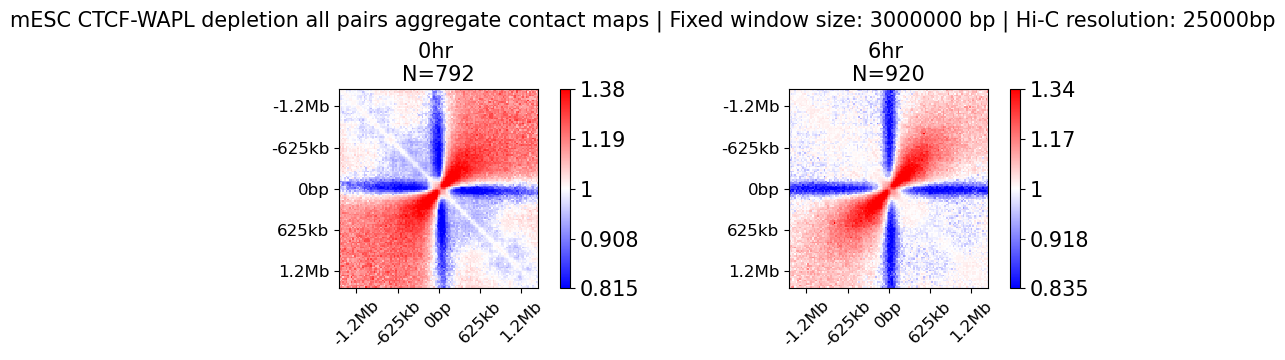

In [7]:
titles = [f"{names_abrev_dict[names[i]]} \nN={len(df_stack[i])}" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"{data_name} aggregate contact maps | Fixed window size: {int(fixed_window_size)} bp | Hi-C resolution: {resolution}bp",
    resolution=resolutions,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=False,
    show=True, 
    vmax=vmaxes,
    vmin=vmins,
    share_xy=False,
    ppr=5,
    figsize=(len(names) * 4.5, 3.5),
    # savepath=f"{save_path}/{data_name}_agg_map-{data_type}_fixed_ws-{fixed_window_size}.png",
    cbar_fontsize=15,
    fig_fontsize=15,
    tick_fontsize=12,
    hide_axis=False,
    center_window=True,
)

## Violin plot of "jet strength"

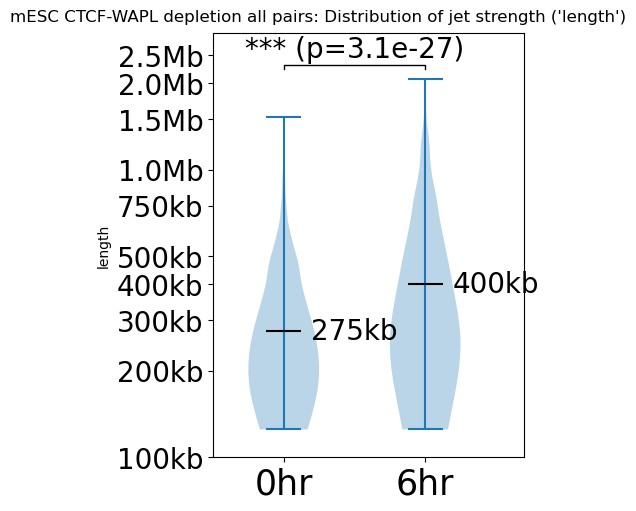

In [8]:
# PLOT JET STRENGTH VIOLIN PLOT OF ALL CALLED
strength_col = "length"  # MIA-Jet "jet strength"

fig, ax = plt.subplots(figsize=(4.5, 5), layout='constrained')

data = [s[strength_col].values for s in table_dict.values()]
positions = np.arange(1, len(data) + 1)

parts = ax.violinplot(data, positions=positions,
                      showmeans=False, showmedians=True, showextrema=True)
for pc in parts['bodies']:
    pc.set_alpha(0.3)

parts['cmedians'].set_color('black')
parts['cmedians'].set_label('median')

# annotate median directly on the figure, next to its line
for pos, d in zip(positions, data):
    med = np.median(d)
    ax.text(pos + 0.5, med, f"{genomic_labels2(med)}",
            color='black', ha='center', va='center', fontsize=20,
            clip_on=False)

labels = [names_abrev_dict[name] for name in table_dict.keys()]

add_pairwise_sig(ax, positions, data, fontsize=20, pad_from_max=-50e3, y_pad=0.11)

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel(strength_col)
ax.tick_params(axis='y', labelsize=20)
ax.tick_params(axis='x', labelsize=25)

ax.set_yscale('log')

# Manual tick positions (bp)
ticks = [
    100e3, 200e3, 300e3, 400e3, 500e3,
    750e3, 1.0e6, 1.5e6, 2e6, 2.5e6
]
ax.yaxis.set_major_locator(FixedLocator(ticks))
ax.yaxis.set_minor_locator(FixedLocator([]))  # no minor ticks
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: genomic_labels2(x)))

# give the right-hand text labels a little room
ax.set_xlim(0.5, len(data) + 0.7)
ax.set_ylim(bottom=100e3, top=3e6)

fig.suptitle(f"{data_name}: Distribution of jet strength ('{strength_col}')")

# plt.savefig(f"{save_path}/{data_name}_{result_type}_summary_violin_{strength_col}.png", dpi=300)
plt.show()